# 10. Robustness & Stress Testing

Notebook 09 selected **Highest Sharpe** (Random Forest, `long_only_top_10_signal_weight`, 21d) as the production candidate: strong net performance, significantly better than random selection (Monte Carlo, **p < 0.002**). But the CAPM regression showed heavy market exposure (**β = 1.827**) and an alpha that is economically large (**38.04%**) with 95% significance (**p = 0.0002**).

A favorable backtest does not certify a strategy, so this notebook is deliberately **adversarial**: instead of looking for more evidence in favor, it asks under what conditions the candidate's performance degrades, loses statistical validity, or disappears.

Five blocks:
1. **§3 Deflated Sharpe Ratio** — audits the search process: could selection bias across the notebook-09 grid explain the result?
2. **§4 Training window & prediction horizon** — does the result depend on the exact choices made at training time?
3. **§5 Universe (sector) sensitivity** — does the signal survive outside the tech-dominated aggregate?
4. **§6 Outlier resistance** — does it depend on a handful of exceptional days, or one rescuing stock per day?
5. **§7 Advanced attribution & stress** — up/down capture, rolling beta/alpha/tracking error, stress resampling, active drawdown.

## 1. Imports & Configuration

Load the libraries, notebook-level constants (prediction horizon, trading calendar, transaction cost, rebalancing frequency), and file paths used throughout this notebook.

### 1.1 Libraries

In [1]:
import sys
import pandas as pd 
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import random
import warnings
import joblib

from pathlib import Path
from scipy.stats import spearmanr
from scipy.stats import norm, skew, kurtosis

# adds the root carpet of the project to the sys.path to allow importing modules from src
sys.path.append(str(Path.cwd().parent))

# autoreload configuration to automatically reload modules when they are modified
%load_ext autoreload
%autoreload 2

### 1.2 Notebook Configuration

In [2]:
# =============================================================================
# Experiment Configuration
# =============================================================================

PREDICTION_HORIZON = 21

TRADING_DAYS_PER_YEAR = 252

RISK_FREE_RATE = 0.0

REBALANCING_FREQUENCY = 21

BASE_TRANSACTION_COST = 0.0015 

FINAL_CANDIDATE = {
    "role": "Highest Sharpe",
    "model": "Random Forest",
    "portfolio": "long_only_top_10_signal_weight",
    "frequency_days": 21,
}

### 1.3 Paths & Global Parameters

In [3]:
# =============================================================================
# Paths
# =============================================================================

BENCHMARK_RETURNS_PATH = "../data/portfolio_results/sp500_benchmark_returns.parquet"

NET_RETURNS_PATH = "../data/portfolio_results/net_portfolio_returns.parquet"

SENSITIVITY_METRICS_PATH = "../data/portfolio_results/rebalancing_frequency_sensitivity_metrics.parquet"

## 2. Data Loading

Load the extended S&P 500 price panel, the **net portfolio returns** from notebook 08, and the **S&P 500 benchmark returns**, and derive daily simple asset returns from adjusted close prices.

In [4]:
# =============================================================================
# Load Extended Price Data
# =============================================================================

prices = pd.read_parquet("../data/raw/sp500_prices_extended.parquet")

# =============================================================================
# Compute Daily Asset Returns
# =============================================================================

adj_close = prices["Adj Close"]

simple_returns = adj_close.pct_change()

# =============================================================================
# Load Net Portfolio Returns
# =============================================================================

net_returns = pd.read_parquet(
    "../data/portfolio_results/net_portfolio_returns.parquet"
)


# =============================================================================
# Load Benchmark Returns
# =============================================================================

sp500_benchmark_returns = pd.read_parquet(
    "../data/portfolio_results/sp500_benchmark_returns.parquet"
)


## 3. Deflated Sharpe Ratio & Multiple-Testing Correction

A high Sharpe found after searching many specifications may be a selection artifact (p-hacking). The **Deflated Sharpe Ratio (DSR)** (Bailey & López de Prado, 2014) corrects the observed Sharpe for **non-normality** (skewness, kurtosis), **sample size**, and the **number of independent trials** evaluated. Full formulation in `docs\10_robustness_stress_testing.md`.


### 3.1 Trial Count & Cross-Sectional Sharpe Variance

The trial count $N$ separates **structural hypotheses** (unique model × weighting-scheme combinations at the 21-day base frequency) from **execution variants** (other rebalancing frequencies, which replay the same signal). Two scenarios are run: **defensible** (distinct signals at 21d) and **conservative** (the full experiment grid). The cross-sectional Sharpe variance measures the dispersion of the searched universe.

In [45]:
# =============================================================================
# 3.1 Trial Count & Sharpe Variance
# =============================================================================

df_full_grid = pd.read_parquet(
    "../data/portfolio_results/rebalancing_frequency_sensitivity_metrics.parquet"
)

# Keep configurations with a valid Sharpe
df_full_grid_valid = df_full_grid.dropna(subset=["Sharpe"]).copy()

# All tested configurations, including rebalancing frequencies
n_trials_full_grid = len(df_full_grid_valid)

# Distinct model × portfolio combinations at 21-day frequency
df_trials = df_full_grid_valid[
    df_full_grid_valid["frequency_days"] == 21
].copy()

n_trials_distinct_signals = (
    df_trials[["model", "portfolio"]]
    .drop_duplicates()
    .shape[0]
)

# Estimate Sharpe variance within each corresponding trial universe
sharpe_variance_full_grid = df_full_grid_valid["Sharpe"].var(ddof=1)
sharpe_variance_21d = df_trials["Sharpe"].var(ddof=1)

print(f"Full-grid trials:             {n_trials_full_grid}")
print(f"Distinct 21-day trials:       {n_trials_distinct_signals}")
print(f"Full-grid Sharpe variance:    {sharpe_variance_full_grid:.5f}")
print(f"21-day Sharpe variance:       {sharpe_variance_21d:.5f}")

Full-grid trials:             210
Distinct 21-day trials:       42
Full-grid Sharpe variance:    0.15791
21-day Sharpe variance:       0.22109


**Clarification**: **N = 42** distinct signals (defensible) and **N = 210** trials (conservative, full grid).

### 3.2 Deflated Sharpe Ratio — Winning Candidate

Audit the winner (Random Forest, Top 10 Signal Weight, 21d): compute the **expected maximum Sharpe by chance** given $N$, then evaluate the observed Sharpe against it with the Probabilistic Sharpe Ratio, using the skewness and raw kurtosis of the daily net returns. A deflated PSR **> 0.95** rejects the hypothesis that the result is a search artifact.

In [46]:
# =============================================================================
# 3.2 Deflated Sharpe Ratio — Winning Candidate
# =============================================================================

from scipy.stats import skew, kurtosis
from src.portfolio.utils import (
    probabilistic_sharpe_ratio,
    expected_max_sharpe,
)

TRADING_DAYS = TRADING_DAYS_PER_YEAR

net_returns = pd.read_parquet(
    "../data/portfolio_results/net_portfolio_returns.parquet"
)

winning_mask = (
    (net_returns["model"] == "Random Forest")
    & (net_returns["portfolio"] == "long_only_top_10_signal_weight")
)

# IMPORTANT:
# If net_returns contains multiple rebalancing frequencies,
# also filter winning_mask to frequency_days == 21.

winning_daily_returns = (
    net_returns.loc[winning_mask, "net_return_base"]
    .dropna()
    .astype(float)
)

metric_mask = (
    (df_full_grid_valid["model"] == "Random Forest")
    & (df_full_grid_valid["portfolio"] == "long_only_top_10_signal_weight")
    & (df_full_grid_valid["frequency_days"] == 21)
)

winning_metrics = df_full_grid_valid.loc[metric_mask, "Sharpe"]

if len(winning_metrics) != 1:
    raise ValueError(
        f"Expected exactly one winning Sharpe, found {len(winning_metrics)}."
    )

# Sharpe from the metrics table, assumed annualized
observed_sharpe_annual = float(winning_metrics.iloc[0])

# Convert to per-observation (daily) Sharpe
observed_sharpe_daily = observed_sharpe_annual / np.sqrt(TRADING_DAYS)

# Distributional moments from daily returns
ret_skew = skew(winning_daily_returns)
ret_kurtosis = kurtosis(winning_daily_returns, fisher=False)
n_obs = len(winning_daily_returns)

# Each variance is measured in the same annualized-Sharpe scale
trial_scenarios = [
    (
        "Conservative (full grid)",
        n_trials_full_grid,
        sharpe_variance_full_grid,
    ),
    (
        "Defensible (distinct signals, 21d)",
        n_trials_distinct_signals,
        sharpe_variance_21d,
    ),
]

dsr_results = {}

for label, n_trials, sr_variance_annual in trial_scenarios:

    # Expected maximum Sharpe in annualized units
    sr_benchmark_annual = expected_max_sharpe(
        sr_variance_annual,
        n_trials,
    )

    # Convert benchmark to daily Sharpe before applying the PSR formula
    sr_benchmark_daily = sr_benchmark_annual / np.sqrt(TRADING_DAYS)

    dsr = probabilistic_sharpe_ratio(
        observed_sharpe_daily,
        sr_benchmark_daily,
        n_obs,
        ret_skew,
        ret_kurtosis,
    )

    dsr_results[label] = {
        "n_trials": n_trials,
        "expected_max_sharpe_by_chance": sr_benchmark_annual,
        "deflated_psr": dsr,
    }

df_dsr = pd.DataFrame(dsr_results).T

print("=" * 90)
print("DEFLATED SHARPE RATIO (RANDOM FOREST — TOP 10 SIGNAL WEIGHT — 21D)")
print("=" * 90)
print(f"Annualized observed Sharpe:   {observed_sharpe_annual:.3f}")
print(f"Daily observed Sharpe:        {observed_sharpe_daily:.4f}")
print(f"Daily Skewness / Kurtosis:    {ret_skew:.3f} / {ret_kurtosis:.3f}")
print(f"Observations (n):             {n_obs}")
print("-" * 90)
print(df_dsr.to_string(formatters={
    "n_trials": lambda x: f"{int(x)}",
    "expected_max_sharpe_by_chance": lambda x: f"{x:.3f}",
    "deflated_psr": lambda x: f"{x:.4f}",
}))
print("-" * 90)

DEFLATED SHARPE RATIO (RANDOM FOREST — TOP 10 SIGNAL WEIGHT — 21D)
Annualized observed Sharpe:   2.474
Daily observed Sharpe:        0.1558
Daily Skewness / Kurtosis:    0.094 / 9.957
Observations (n):             357
------------------------------------------------------------------------------------------
                                   n_trials expected_max_sharpe_by_chance deflated_psr
Conservative (full grid)                210                         1.105       0.9447
Defensible (distinct signals, 21d)       42                         1.039       0.9529
------------------------------------------------------------------------------------------



Expected maximum Sharpe by chance: **1.039** (N = 42) and **1.105** (N = 210), against an observed Sharpe of **2.474**. The series has heavy tails (**raw kurtosis 9.957**) over **357** daily observations. The **deflated PSR is 0.9447 and 0.9529** in the two scenarios.

**Decision:** The observed Sharpe remains statistically significant after correcting for multiple testing under the defensible 21-day trial-count assumption (DSR = 0.9529), but falls marginally below the 95% confidence threshold under the conservative full-grid assumption (DSR = 0.9447). Selection bias alone is therefore unlikely to fully explain the result, although the evidence is not robust to the choice of trial-count assumption. DSR does not address sample-length sensitivity or regime dependence; these are examined separately in §6–7.


## 4. Training Window & Prediction Horizon Sensitivity

Retrain the winning architecture (**Random Forest + Top 10 Signal Weight**) over a small grid of **training windows** (expanding from 2011, rolling 5-year from 2020) and **prediction horizons** (5, 10, 21 days) — **6 configurations**. Only the winning architecture is tested, to avoid tripling compute cost. Rebalancing is held at **21 days** so the prediction-horizon effect is isolated from the rebalancing-frequency effect already measured in notebook 09 §5.

### 4.1 Setup and Configuration

Define the experiment grid, sample boundaries, features, and portfolio-construction parameters (identical to the final model).

In [20]:
import json
from sklearn.ensemble import RandomForestRegressor


from src.portfolio.constraints import apply_turnover_constraint_with_drift
from src.portfolio.metrics import calculate_performance_metrics

# --- Experiment grid ---------------------------------------------------------
HORIZONS = [5, 10, 21]
WINDOWS = ["expanding", "rolling_5y"]
TRAIN_START = {
    "expanding": pd.Timestamp("2011-01-03"),
    "rolling_5y": pd.Timestamp("2020-01-01"),
}

# --- Sample split ------------------------------------------------------------
TRAIN_END = pd.Timestamp("2024-11-27")
OOS_START = pd.Timestamp("2025-01-15")
OOS_END = pd.Timestamp("2026-06-18")

# --- Features and universe ---------------------------------------------------
FEATURES_RANK = [
    "momentum_12_1_win_rank",
    "upside_volatility_win_rank",
    "log10_amihud_win_rank",
]
FACTOR_COLS = ["momentum_12_1", "upside_volatility", "log10_amihud"]
EXCLUDED_OOS_TICKERS = ["SW", "AMCR"]

# --- Portfolio construction --------------------------------------------------
MODEL_LABEL = "Random Forest"
TOP_DECILE = 10
SIGNAL_WEIGHTING_K = 1.0
MAX_POSITION_WEIGHT = 0.05
MIN_EFFECTIVE_WEIGHT = 0.005
MAX_TURNOVER_DESIGN = 0.25
REBALANCING_DAYS_FIXED = 21  # fixed to isolate the horizon effect (see 09 §5)
BASE_TRANSACTION_COST = 0.0015  # 15 bps, same as notebook 09


# --- Paths -------------------------------------------------------------------
UNIVERSE_PATH = "../data/universe_496.json"
MODEL_CONFIG_PATH = "../data/model_results/final_model/final_model_configurations.json"
TRAIN_FEATURES_PATH = "../data/preprocessed/df_final_rank.parquet"
PRICES_PATH = "../data/raw/sp500_prices_extended.parquet"

### 4.2 Data Preparation

Load the frozen universe, the tuned Random Forest hyperparameters, the training features, and the extended price history. OOS features are rebuilt from prices with the training pipeline: factor computation, cross-sectional winsorization, cross-sectional ranking.

In [21]:
from src.portfolio.hyperparameter_sensitivity import (
    load_frozen_universe,
    load_rf_params,
    load_train_features,
    load_extended_prices,
    build_oos_features
)

frozen_tickers = load_frozen_universe()
rf_params = load_rf_params()

X_train_features = load_train_features(frozen_tickers)

prices_ext = load_extended_prices(frozen_tickers)
adj_close_ext = prices_ext["Adj Close"]
simple_returns_ext = adj_close_ext.pct_change()
log_returns_ext = np.log(adj_close_ext / adj_close_ext.shift(1))

X_oos_features = build_oos_features(prices_ext, simple_returns_ext, log_returns_ext)

### 4.3 Model Training and OOS Predictions

Refit the Random Forest for each (horizon, window) pair and predict on the OOS period. Forward returns missing at the OOS tail are used only for evaluation, never for trading.

In [22]:
from src.portfolio.hyperparameter_sensitivity import run_prediction_grid

oos_predictions_dict = run_prediction_grid(
    X_train_features, X_oos_features, adj_close_ext, rf_params
)


--- Horizon: 5 days ---
  -> Training window: expanding
  -> Training window: rolling_5y

--- Horizon: 10 days ---
  -> Training window: expanding
  -> Training window: rolling_5y

--- Horizon: 21 days ---
  -> Training window: expanding
  -> Training window: rolling_5y

Predictions generated for all configurations.


### 4.4 Portfolio Construction

Build the Long-Only Top 10 Signal Weight portfolio for each configuration with the same pipeline as the final model (decile selection → re-rank within selection → rank^K signal weights → max/min weight constraints → turnover constraint with drift at 21 days). Details in `docs/08_portfolio_construction.md`.

In [23]:
from src.portfolio.hyperparameter_sensitivity import (
    build_top_decile_weights,
    apply_weight_constraints,
)

all_portfolio_weights = pd.concat(
    [
        build_top_decile_weights(pred_df["prediction_rf"], horizon, window)
        for (horizon, window), pred_df in oos_predictions_dict.items()
    ],
    ignore_index=True,
)

all_portfolio_weights_constrained = apply_weight_constraints(all_portfolio_weights)

rebalance_weights_constrained, daily_weights_constrained = (
    apply_turnover_constraint_with_drift(
        portfolio_weights=all_portfolio_weights_constrained,
        simple_returns=simple_returns_ext,
        rebalancing_days=REBALANCING_DAYS_FIXED,
        max_turnover_design=MAX_TURNOVER_DESIGN,
        min_weight=MIN_EFFECTIVE_WEIGHT,
        max_weight=MAX_POSITION_WEIGHT,
    )
)

### 4.5 Backtest: Gross Returns, Turnover, and Costs

The engine runs on returns truncated at `OOS_END`. **Turnover** is measured against drifted previous weights; **gross returns** are daily with weights drifting between rebalances; **transaction costs** are charged on the trading day after each rebalance date.

In [24]:
from src.portfolio.hyperparameter_sensitivity import compute_net_returns

final_grid_net_returns = compute_net_returns(
    rebalance_weights_constrained,
    simple_returns_ext,
    OOS_END,
    BASE_TRANSACTION_COST,
)

### 4.6 Sensitivity Results

Net-return metrics (base costs) for every configuration, summarized as a window × horizon table of net Sharpe ratios.

In [25]:
from src.portfolio.hyperparameter_sensitivity import parse_portfolio_name

performance_metrics_grid = calculate_performance_metrics(
    final_grid_net_returns, return_col="net_return_base", verbose=True
)

parsed = performance_metrics_grid["portfolio"].map(parse_portfolio_name)
performance_metrics_grid["horizon"] = [h for h, _ in parsed]
performance_metrics_grid["window"] = [w for _, w in parsed]

sharpe_sensitivity_table = performance_metrics_grid.pivot(
    index="window", columns="horizon", values="Sharpe"
)

print("\n" + "=" * 80)
print("SENSITIVITY TABLE: NET SHARPE RATIO (Random Forest Top 10)")
print("=" * 80)
print(
    sharpe_sensitivity_table.to_string(
        formatters={col: lambda x: f"{x:.3f}" for col in sharpe_sensitivity_table.columns}
    )
)
print("=" * 80)

3.1 — NET PORTFOLIO PERFORMANCE
✓ Strategies evaluated = 6
✓ Models evaluated = 1
✓ Date range = 2025-01-16 → 2026-06-18
✓ Missing performance metrics = 0

        model             portfolio   CAGR Ann_vol Sharpe Sortino Calmar  max_DD  max_underwater_in_days
Random Forest  top_10_5d_rolling_5y 92.79%  33.16%  2.798   4.165  3.128 -29.67%                      86
Random Forest top_10_10d_rolling_5y 91.50%  34.51%  2.651   3.914  3.006 -30.44%                      86
Random Forest   top_10_5d_expanding 86.39%  33.56%  2.574   3.820  2.905 -29.74%                      85
Random Forest top_10_21d_rolling_5y 89.15%  35.18%  2.534   3.739  2.826 -31.55%                      86
Random Forest  top_10_10d_expanding 84.76%  34.08%  2.487   3.677  2.795 -30.32%                      84
Random Forest  top_10_21d_expanding 82.45%  34.94%  2.360   3.474  2.578 -31.98%                      86

SENSITIVITY TABLE: NET SHARPE RATIO (Random Forest Top 10)
horizon       5     10    21
window              

**Clarification:** The methodology used to calculate these metrics differs slightly from that of previous notebooks. However, since all strategies are evaluated consistently, the results are suitable for comparing their relative performance within this analysis. Direct comparisons with metrics from previous notebooks should be treated with caution.

### 4.7 Comparability with the Final Model

This section is an independent retraining, so absolute levels differ slightly: the (21d, expanding) configuration reaches a **CAGR of ~82%** vs. **~89%** for the final model. For that configuration:
- Average cross-sectional **rank correlation** between retrained and final predictions: **~0.98**.
- **Top-decile overlap: ~86%**; the differences are names near the 90th-percentile cut, enough to move a concentrated long-only CAGR by several points.
- Universe differences: GEV and SOLV (missing in the final model's file until late March 2025) and FISV (missing on a few isolated dates).
- **~44 names per date, not 50**, because position constraints are applied after selection (identical in every configuration).

**How to read the results:** compare configurations with each other, not against the final model's absolute numbers; the final model remains the reference.

**Limitation:** the 82% vs. 89% gap is not negligible. We attribute it to training variability plus boundary changes, but have not measured it. Repeating (21d, expanding) with several seeds would show whether both values fall in the same range. Conclusions about rolling vs. expanding are reliable only if their difference clearly exceeds this gap.

## 5. Universe (Sector) Sensitivity

Same winning candidate (Random Forest, same prediction horizon and rebalancing frequency), with the starting universe restricted to **one sector at a time**: Technology, Industrials, Financial Services, and Healthcare. The goal is to check whether the signal survives outside the sector composition that dominates the aggregate result — relevant because the OOS period coincides with a **rally concentrated in technology**.

Design:
- Within each sector, predictions are re-ranked and the top 1, 2, or 3 deciles selected (**Top 10 / 20 / 30**). **Top 20 is the primary cut, fixed before looking at any performance**; the others are robustness checks.
- Position limits are rescaled to the number of selected names so the relative slack of the caps matches the main portfolio.
- Each portfolio is compared against an **equal-weight benchmark of its own sector**, and also run without the turnover constraint.
- Backtests use the same engine and costs as §4 (21-day rebalancing).

### 5.1 Setup and Configuration

In [12]:
# --- Experiment design -------------------------------------------------------
SECTORS = ["Technology", "Industrials", "Financial Services", "Healthcare"]
CUTS = {"top_10": 1, "top_20": 2, "top_30": 3}  # number of deciles included
PRIMARY_CUT = "top_20"  # fixed before looking at performance
N_REF = 50  # names in the main portfolio (10% of 496)
FINAL_PORTFOLIO = "long_only_top_10_signal_weight"
OOS_PRED_START = "2025-01-16"

# --- Paths -------------------------------------------------------------------
SECTORS_PATH = Path("../data/raw/ticker_sectors.csv")
FINAL_WEIGHTS_PATH = "../data/portfolio_results/final_portfolio_weights.parquet"
OOS_PREDICTIONS_PATH = "../data/model_results/final_model/oos/oos_predictions.parquet"

# --- Yahoo Finance download --------------------------------------------------
YAHOO_ALIAS = {}  # tickers Yahoo does not recognize under the same symbol
MAX_RETRIES = 3
SLEEP_BETWEEN_CALLS = 0.3
SLEEP_ON_RETRY = 3.0
SAVE_EVERY = 100
MANUAL_SECTORS = {  # tickers Yahoo fails to resolve
    "FISV": {
        "yahoo_symbol": "FISV",
        "sector": "Technology",
        "industry": "Information Technology Services",
    },
}

### 5.2 Sector Mapping

Map each ticker to a sector using Yahoo Finance (**checkpointed download**, resumable after interruptions), with a manual patch for tickers Yahoo cannot resolve (e.g., FISV). Full coverage of the frozen universe is required; coverage is reported before and after the patch. Design rationale in `docs/10_robustness_stress_testing.md`.

In [33]:
from src.portfolio.sector_sensitivity import (
    download_sectors,
    patch_manual_sectors,
    report_sector_coverage,
)

sectors_df = download_sectors(list(frozen_tickers), SECTORS_PATH)
report_sector_coverage(sectors_df)

sectors_df = patch_manual_sectors(SECTORS_PATH, MANUAL_SECTORS)
report_sector_coverage(sectors_df)

Pending: 0 of 496
Tickers with sector: 496 / 496
Missing (0): []

Tickers per sector:
sector
Technology                83
Industrials               73
Financial Services        70
Healthcare                59
Consumer Cyclical         52
Consumer Defensive        33
Real Estate               31
Utilities                 31
Communication Services    23
Energy                    21
Basic Materials           20
Name: count, dtype: int64
Tickers with sector: 496 / 496
Missing (0): []

Tickers per sector:
sector
Technology                83
Industrials               73
Financial Services        70
Healthcare                59
Consumer Cyclical         52
Consumer Defensive        33
Real Estate               31
Utilities                 31
Communication Services    23
Energy                    21
Basic Materials           20
Name: count, dtype: int64


### 5.3 Sector Exposure of the Winning Model

Before stress-testing within sectors, diagnose the **de facto sector concentration** of the final portfolio: project daily weights and prediction rankings onto the sector map. Sectors with no selected names on a date are imputed as **zero**, not NaN, so average exposure is unconditional.

In [34]:
from src.portfolio.sector_sensitivity import (
    load_final_holdings,
    load_global_rank,
    sector_exposure_summary,
    sector_holdings_stats
)

final_portfolio_weights = pd.read_parquet(FINAL_WEIGHTS_PATH)
sector_map = pd.read_csv(SECTORS_PATH).set_index("ticker")["sector"]

holdings = load_final_holdings(final_portfolio_weights, sector_map)
global_rank, sector_of = load_global_rank(OOS_PREDICTIONS_PATH, sector_map, final_portfolio_weights)

print(sector_exposure_summary(holdings, sector_map).round(3))
print(sector_holdings_stats(holdings, SECTORS))

                        avg_names  avg_weight  universe_share
sector                                                       
Technology                 16.202       0.394           0.167
Communication Services      4.508       0.127           0.046
Industrials                 6.379       0.114           0.147
Consumer Cyclical           4.863       0.098           0.105
Healthcare                  4.379       0.090           0.119
Financial Services          2.677       0.076           0.141
Utilities                   2.315       0.051           0.062
Energy                      1.339       0.023           0.042
Basic Materials             1.113       0.023           0.040
Real Estate                 0.113       0.001           0.062
Consumer Defensive          0.113       0.001           0.067
                    n_min  n_median  n_max  days_with_zero  weight_mean
Technology           13.0      16.0   21.0             0.0        0.394
Industrials           5.0       6.0    8.0        

**Interpretation** Technology dominates the portfolio, representing 39.4% of average portfolio weight and approximately 16 holdings on average (median: 16; range: 13–21). Communication Services (12.7%), Industrials (11.4%), Consumer Cyclical (9.8%) and Healthcare (9.0%) are the next-largest sectors. Technology is substantially overweight relative to its 16.7% share of the investment universe, while several sectors have limited or negligible exposure.

**Decision:** The strategy exhibits a pronounced Technology tilt, so its alpha cannot be attributed exclusively to stock-picking. However, these sector weights alone cannot establish how much performance comes from sector allocation versus stock selection; a sector-neutral or sector-adjusted benchmark is needed to distinguish the two effects.

### 5.4 Within-Sector Universe Audit

For each sector and cut, report the minimum, median, and maximum number of names per date, and the smallest feasible position cap (with N positions, `max_weight >= 1/N` is required for weights to sum to one).

In [35]:
from src.portfolio.sector_sensitivity import audit_sector_universe

audit, feasible_max_weight = audit_sector_universe(global_rank, sector_of, SECTORS, CUTS)
print(audit)
print(feasible_max_weight)

                                min  median   max
sector             metric                        
Technology         n_universe  82.0    83.0  83.0
                   top_10       9.0     9.0   9.0
                   top_20      17.0    17.0  17.0
                   top_30      25.0    25.0  25.0
Industrials        n_universe  72.0    73.0  73.0
                   top_10       8.0     8.0   8.0
                   top_20      15.0    15.0  15.0
                   top_30      22.0    22.0  22.0
Financial Services n_universe  70.0    70.0  70.0
                   top_10       7.0     7.0   7.0
                   top_20      14.0    14.0  14.0
                   top_30      21.0    21.0  21.0
Healthcare         n_universe  58.0    59.0  59.0
                   top_10       6.0     6.0   6.0
                   top_20      12.0    12.0  12.0
                   top_30      18.0    18.0  18.0
                    top_10  top_20  top_30
Technology           0.111   0.059   0.040
Industrials   

### 5.5 Within-Sector Portfolio Construction & Constraint Rescaling

Confining the model to one sector neutralizes sector rotation, so any alpha reflects stock-picking. A sector sub-universe of ~60 names yields a top decile of ~6, so the main portfolio's **5% cap would leave up to 70% uninvested**; position limits are therefore rescaled to the selected-name count, and the turnover constraint (with drift) is applied as in the main strategy. Rationale in `docs/10_robustness_stress_testing.md`.

In [36]:
from src.portfolio.sector_sensitivity import build_sector_portfolios

sector_results = build_sector_portfolios(
    global_rank, sector_of, SECTORS, CUTS, simple_returns_ext
)

technology_top_10: N_min=9, max_weight=0.255
technology_top_20: N_min=17, max_weight=0.142
technology_top_30: N_min=25, max_weight=0.098
industrials_top_10: N_min=8, max_weight=0.283
industrials_top_20: N_min=15, max_weight=0.159
industrials_top_30: N_min=22, max_weight=0.111
financial_services_top_10: N_min=7, max_weight=0.319
financial_services_top_20: N_min=14, max_weight=0.170
financial_services_top_30: N_min=21, max_weight=0.116
healthcare_top_10: N_min=6, max_weight=0.364
healthcare_top_20: N_min=12, max_weight=0.196
healthcare_top_30: N_min=18, max_weight=0.134


### 5.6 Sector Benchmarks and Backtest

Each sector gets an equal-weight benchmark over its full within-sector universe. All portfolios (constrained, unconstrained, benchmarks) are aligned to a common rebalancing calendar and backtested with the §4 engine. Checks: calendars match, benchmark weights sum to one on every date, return series start and end on the same day.

In [37]:
from src.portfolio.sector_sensitivity import (
    build_sector_benchmark_weights,
    assemble_rebalance_weights,
    compute_net_returns,
    slug,
)

benchmarks = {
    s: build_sector_benchmark_weights(global_rank, s, f"{slug(s)}_equal_weight", sector_map)
    for s in SECTORS
}

all_rebalance = assemble_rebalance_weights(sector_results, benchmarks, OOS_END)

sector_net_returns = compute_net_returns(
    all_rebalance, simple_returns_ext, OOS_END, BASE_TRANSACTION_COST
)

returns_wide = sector_net_returns.pivot(index="date", columns="portfolio", values="net_return_base")
assert returns_wide.notna().all().all(), "Series do not start and end on the same day"

### 5.7 Performance vs. Sector Benchmarks

Each portfolio is evaluated against its **own sector's equal-weight benchmark**, so excess return reflects selection skill rather than sector cycle. Metrics: **Sharpe differential**, **Tracking Error**, and **Information Ratio**.

In [38]:
from src.portfolio.sector_sensitivity import (
    calculate_performance_metrics,
    label_portfolios,
    compare_to_benchmark,
    add_active_stats,
    format_sector_table
)

perf = calculate_performance_metrics(sector_net_returns, verbose=False)
perf = label_portfolios(perf, SECTORS, CUTS)

sector_perf = compare_to_benchmark(perf)
sector_perf = add_active_stats(sector_perf, returns_wide, TRADING_DAYS_PER_YEAR)

print(format_sector_table(sector_perf))

            sector    cut    CAGR bench_CAGR excess_CAGR Sharpe bench_Sharpe delta_Sharpe Sortino Calmar  max_DD bench_max_DD     TE    IR
Financial Services top_20  31.36%      9.88%      21.48%  1.136        0.515        0.621   1.770  1.404 -22.34%      -17.80% 14.87% 1.333
        Healthcare top_20  20.17%      4.67%      15.51%  0.679        0.264        0.415   0.992  0.720 -28.02%      -14.53% 16.99% 0.981
       Industrials top_20  51.00%     19.55%      31.44%  1.627        0.962        0.665   2.500  1.739 -29.33%      -20.39% 15.74% 1.665
        Technology top_20 146.99%     36.76%     110.23%  3.063        1.401        1.661   4.539  3.925 -37.45%      -25.93% 28.82% 2.337


**Interpretation:** Under the primary Top 20 cut, all four evaluated sectors outperform their respective benchmarks. Technology delivers the strongest results, with a 146.99% CAGR, 110.23 percentage points of excess CAGR and a 1.661 improvement in Sharpe ratio. Industrials also performs strongly, with 31.44 percentage points of excess CAGR, followed by Financial Services (21.48 pp) and Healthcare (15.51 pp).

**Decision:** The signal shows positive performance within all four evaluated sectors, suggesting that the results are not solely driven by the overall Technology overweight. However, Technology remains the strongest contributor, and the evidence is limited to these four sectors and the Top 20 cut. Top 10 and Top 30 results are needed to assess robustness across selection thresholds.

## 6. Outlier Resistance

CAPM beta and alpha (Newey-West) were estimated in notebook 09, so this section asks a different question: does the final candidate's performance depend on a handful of exceptional observations? Two tests:

1. **Time-series:** replace the best N days with zero returns, for both strategy and S&P 500.
2. **Cross-sectional:** remove the single best-contributing stock from the portfolio every day.

If the Sharpe holds in both, the result is not driven by a few lucky days or one rescuing stock per day.

**Scope.** These tests do not address sample length: the OOS period is short (~18 months) and covers a single market regime.

### 6.1 Setup and Configuration

In [7]:
import matplotlib.dates as mdates

# --- Evaluation window -------------------------------------------------------
BENCH_START = "2025-01-16"
BENCH_END = "2026-06-18"
TRADING_DAYS_PER_YEAR = 252

# --- Outlier tests -----------------------------------------------------------
N_DROP = 5
CROSS_SECTIONAL_COST_PROXY = 0.05  # fraction of the mean daily net return, used as a cost proxy

### 6.2 Series Alignment & CAPM Baseline

Align strategy and benchmark returns on the exact common calendar and re-estimate CAPM with Newey-West (HAC) errors, the monthly rebalancing induces serial dependence that would otherwise inflate t-statistics and p-values.

In [8]:
from src.portfolio.robustness import (
    load_benchmark_returns,
    align_series,
    fit_capm_newey_west,
    print_capm_summary,
    get_strategy_returns
) 

s_bmk_returns = load_benchmark_returns(BENCHMARK_RETURNS_PATH)
s_strategy, s_bmk_aligned = align_series(
    get_strategy_returns(net_returns, FINAL_CANDIDATE), s_bmk_returns
)

capm = fit_capm_newey_west(s_strategy, s_bmk_aligned)
print_capm_summary(capm, FINAL_CANDIDATE["role"])

CAPM BETA - Highest Sharpe (Newey-West, lags=21)
beta             = 1.827  (t=20.81)
annualized alpha = 38.04%  (p=0.0002)
R-squared        = 0.775


**Interpretation:** Over the evaluation window, the strategy exhibits an estimated beta of 1.827 and an annualized alpha of 38.04%, statistically significant at conventional levels (p = 0.0002). The regression has an \(R^2\) of 0.775, indicating that the market benchmark explains 77.5% of the variation in strategy returns. These results suggest substantial market exposure alongside positive risk-adjusted performance, although the alpha remains conditional on the CAPM specification and the evaluation window.

### 6.3 Drop the Best N Days (N = 5)

Heavy-tailed returns mean a strong Sharpe can hinge on a few extreme days. Setting the **5 best days** of both strategy and index to zero simulates losing those events. If the penalized strategy Sharpe stays above the penalized benchmark, the edge is recurrent, not episodic.

In [9]:
from src.portfolio.robustness import (
    best_days_test,
    print_robustness_table
)

N_DROP = 5  # Number of best days to drop for robustness testing

outlier_robustness_df, penalized, dropped = best_days_test(
    s_strategy, s_bmk_aligned, FINAL_CANDIDATE["role"]
)

fmt_dates = lambda dates: [d.strftime("%Y-%m-%d") for d in dates]
print_robustness_table(
    outlier_robustness_df,
    f"OUTLIER RESISTANCE TEST: PENALIZING THE BEST {N_DROP} DAYS",
    notes=[
        f"Strategy lost days:  {fmt_dates(dropped['strategy'])}",
        f"Benchmark lost days: {fmt_dates(dropped['benchmark'])}",
    ],
)

s_strategy_penalized = penalized["strategy"]
s_bmk_penalized = penalized["benchmark"]
strat_top_dates = dropped["strategy"]

OUTLIER RESISTANCE TEST: PENALIZING THE BEST 5 DAYS
                Portfolio               State   CAGR    Vol Sharpe
      S&P 500 (Benchmark)            Original 17.76% 17.49%  1.016
      S&P 500 (Benchmark) Missing Best 5 Days  2.17% 14.85%  0.146
Highest Sharpe (Strategy)            Original 89.75% 36.28%  2.474
Highest Sharpe (Strategy) Missing Best 5 Days 48.57% 32.83%  1.479
------------------------------------------------------------------------------------------
Strategy lost days:  ['2025-04-09', '2026-03-31', '2025-05-12', '2026-02-06', '2025-04-24']
Benchmark lost days: ['2025-04-09', '2025-05-12', '2026-03-31', '2025-04-22', '2026-04-08']


**Interpretation:** Excluding the five best days reduces the strategy’s Sharpe from 2.474 to 1.479, versus 1.016 to 0.146 for the benchmark.

**Decision:** The strategy retains its performance advantage, suggesting its results are not solely driven by a handful of exceptional days.

### 6.4 Geometric Impact: Wealth Index

Because returns compound, removing the best days damages the equity curve geometrically. The plot compares base-100 wealth for original vs. penalized series and marks the dropped days.

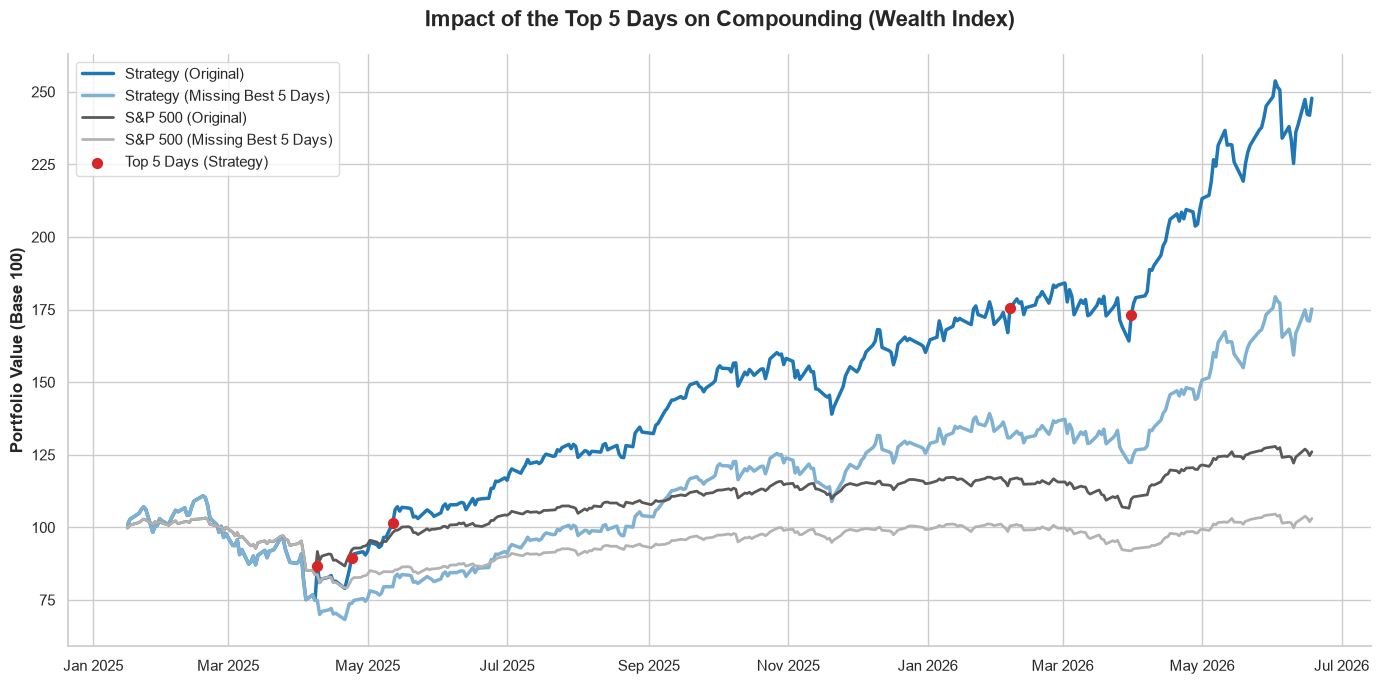

In [10]:
from src.portfolio.robustness import (plot_wealth_index)

plot_wealth_index(s_strategy, s_strategy_penalized, s_bmk_aligned, s_bmk_penalized, strat_top_dates)

### 6.5 Cross-Sectional Test: Drop the Top Contributor Daily

Each day the single stock with the highest gross contribution is removed ex post — an extreme test of whether one "hero" stock carries the other nine.

**Limitation.** The penalized series is built from gross contributions minus a rough cost proxy (a small fraction of the mean daily net return), not actual transaction costs. Compare with the original net series as an order of magnitude.

In [15]:
from src.portfolio.robustness import (
    cross_sectional_drop_best_stock,
    metrics_row
    )

final_weights = pd.read_parquet(FINAL_WEIGHTS_PATH)

s_cross_penalized = cross_sectional_drop_best_stock(
    final_weights, FINAL_CANDIDATE, simple_returns_ext, s_strategy
)

role = FINAL_CANDIDATE["role"]
cross_robustness_df = pd.DataFrame(
    [
        metrics_row(role, "Original (Net)", s_strategy),
        metrics_row(role, "Missing the BEST STOCK every single day", s_cross_penalized),
    ]
)

print_robustness_table(
    cross_robustness_df,
    "CROSS-SECTIONAL OUTLIER TEST: DROPPING THE #1 CONTRIBUTOR EVERY DAY",
)

CROSS-SECTIONAL OUTLIER TEST: DROPPING THE #1 CONTRIBUTOR EVERY DAY
     Portfolio                                   State   CAGR    Vol Sharpe
Highest Sharpe                          Original (Net) 89.75% 36.28%  2.474
Highest Sharpe Missing the BEST STOCK every single day  0.26% 40.45%  0.006


**Interpretation:** Removing the best-performing stock each day reduces the strategy’s Sharpe from 2.474 to 0.006.

**Decision:** **Fail.** The strategy does not pass this robustness test, as its performance almost entirely disappears when the daily top contributor is excluded.

## 7. Advanced Attribution and Active-Risk Stability

Four tests of how the market exposure and the active risk of the final candidate behave:

1. **Up/down capture:** asymmetry between rising and falling markets.
2. **Rolling CAPM and tracking error:** time-variation of beta, alpha and active risk.
3. **Stress resampling:** performance in synthetic stress scenarios.
4. **Active drawdown:** worst relative underperformance against the S&P 500.

### 7.1 Setup and Configuration

In [5]:
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter

# --- Rolling CAPM ------------------------------------------------------------
ROLLING_WINDOW = 60

# --- Stress resampling -------------------------------------------------------
N_BOOTSTRAP = 2000
BLOCK_SIZE = 21              # matches the holding period
SYNTHETIC_YEAR_BLOCKS = 12   # 12 blocks x 21 days = 252 trading days
STRESS_PERCENTILE = 33       # keep the worst third of benchmark blocks
BOOTSTRAP_SEED = 42

### 7.2 Up/Down Market Capture Ratios

Excess return can be misleading if it comes from indiscriminate procyclical leverage. Sessions are split by sign of the S&P 500 and **arithmetic daily-mean returns** are compared (avoiding the distortions of compounding on one-sided partitions). **High up-capture consistent with beta, combined with materially lower down-capture**, would indicate defensive alpha from stock selection rather than market exposure.


UP/DOWN MARKET CAPTURE RATIOS (DAILY AVERAGE METHOD)
Total Days Analyzed: 357 (204 Up / 153 Down)
------------------------------------------------------------------------------------------
             Metric Benchmark Avg Return Strategy Avg Return Capture Ratio
  Up-Market Capture               0.690%              1.462%        211.7%
Down-Market Capture              -0.755%             -1.294%        171.4%
------------------------------------------------------------------------------------------
Capture Spread (Asymmetry): 40.3% (Higher is better)


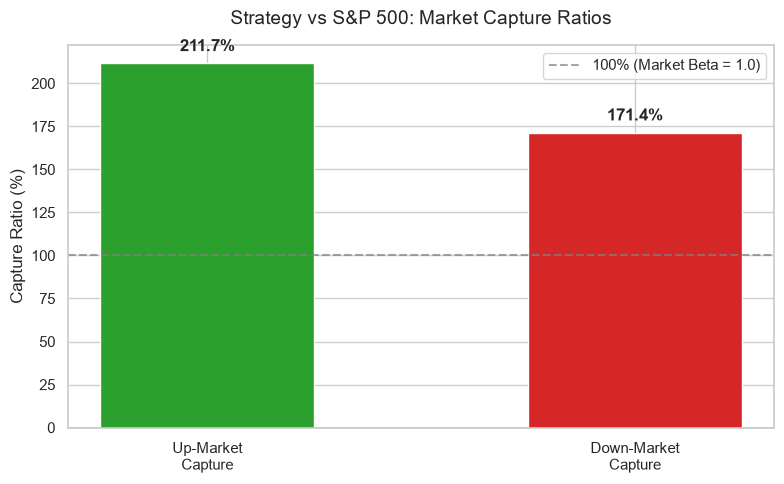

In [16]:
from src.portfolio.attribution import (
    calculate_capture_ratio_daily,
    print_capture_summary,
    plot_capture_ratios
)

capture_metrics = calculate_capture_ratio_daily(s_strategy, s_bmk_aligned)
print_capture_summary(capture_metrics)
plot_capture_ratios(capture_metrics)

**Interpretation:** The strategy captures 211.7% of benchmark gains but also experiences 171.4% of benchmark losses, yielding a capture spread of 40.3%.

**Decision:** Positive asymmetry, but downside exposure remains amplified. The strategy participates more strongly in both up and down markets.

### 7.3 Rolling CAPM & Tracking Error (60 Days)

Static full-sample metrics assume stationarity. A **60-day rolling CAPM** tracks three things: **beta** (erratic spikes in directional exposure?), **alpha** (persistent, or concentrated in a few months?), and **tracking error** (aggressiveness of deviations from the index). Rolling estimates are plain OLS point estimates, not significance tests.

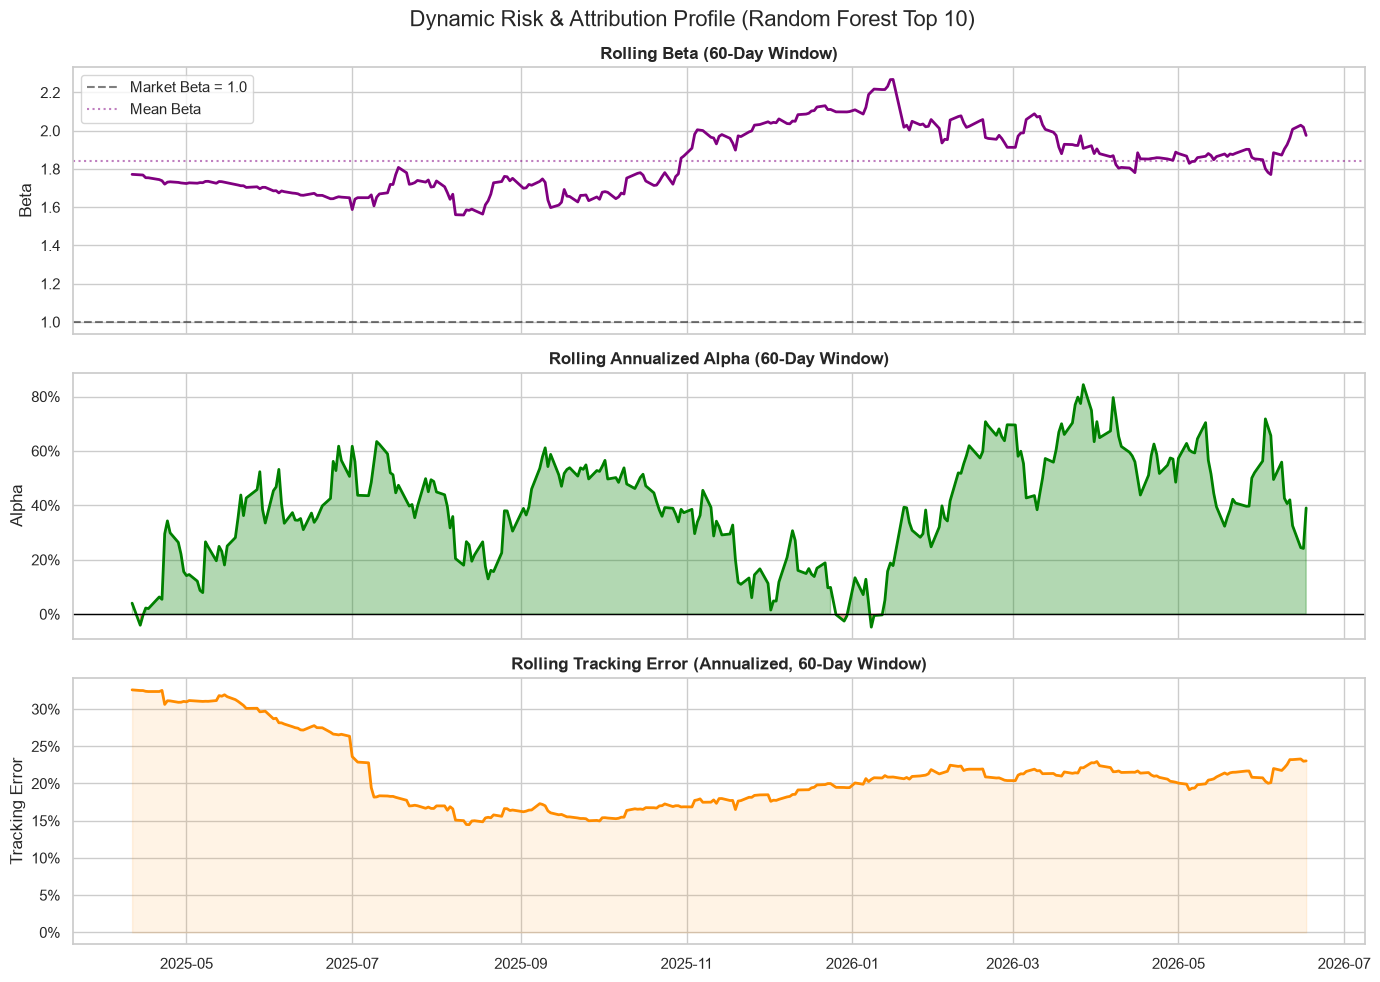

DYNAMIC RISK SUMMARY (Rolling 60 Days)
                    mean    min    max    std
Rolling_Beta       1.842  1.559  2.268  0.163
Rolling_Alpha_Ann  0.398 -0.048  0.844  0.192
Rolling_TE_Ann     0.211  0.145  0.326  0.048


In [17]:
from src.portfolio.attribution import (
    rolling_capm_tracking_error,
    plot_rolling_risk,
    print_rolling_summary
)

df_dynamic_risk = rolling_capm_tracking_error(s_strategy, s_bmk_aligned)
plot_rolling_risk(df_dynamic_risk)
print_rolling_summary(df_dynamic_risk)

- **Beta:** mean **1.842**, range **1.55–2.26** — high but **stable**; no spikes in stress.
- **Alpha:** mean **39.8%** annualized, range **−4.8% to +84%** — positive in the vast majority of windows, consistent with the full-sample alpha in §6.2.
- **Tracking error:** mean **21.1%**, in line with a 10-stock concentrated portfolio.

**Takeaway:** market exposure is high but predictable, and alpha does not depend on a single peak.

### 7.4 Stress Resampling

A standard bootstrap over a strongly bullish window inherits positive returns. **Stress resampling** splits S&P 500 history into overlapping 21-day blocks (matching the holding period), keeps only the **worst third**, and chains 12 blocks (one synthetic year) drawn with replacement from that pool, **N = 2000** times, preserving the cross-asset covariance structure. Rationale in `docs/10_robustess_stress_testing.md`.

In [18]:
from src.portfolio.attribution import (
    build_stress_pool,
    simulate_stress_years,
    stress_results_table,
    print_stress_results
)

valid_starts, stressed_starts, stress_threshold = build_stress_pool(s_bmk_aligned)

strat_synth, bmk_synth = simulate_stress_years(s_strategy, s_bmk_aligned, stressed_starts)

df_stress_results, strat_win_rate = stress_results_table(
    strat_synth, bmk_synth, FINAL_CANDIDATE["role"]
)
print_stress_results(
    df_stress_results, strat_win_rate,
    len(valid_starts), len(stressed_starts), stress_threshold,
)

CONDITIONAL BOOTSTRAP: 2000 SYNTHETIC STRESS YEARS
Total overlapping blocks available: 337
Stressed blocks pool (worst 33%): 111
Stress threshold (max S&P 500 return in these blocks): 0.18%
----------------------------------------------------------------------------------------------------
                Portfolio Mean Synthetic CAGR 95% CI Low 95% CI High % of Years Profitable
      S&P 500 (Benchmark)             -33.49%    -46.82%     -20.21%                  0.0%
Highest Sharpe (Strategy)             -38.83%    -64.22%      -6.13%                  1.2%
----------------------------------------------------------------------------------------------------
Strategy Outperformance Rate (beats benchmark in stress): 26.7%


**Interpretation:** In the synthetic stress scenario (S&P 500 at **−33.5% annualized**), the strategy returns **−38.8%** and beats the index in only **26.7%** of simulations — the expected consequence of **β ≈ 1.84** in a long-only, always-invested portfolio. The loss is smaller than a beta-only projection (beyond −50%), so selection absorbs part of the blow, but a purely directional long-only strategy cannot neutralize a sustained systemic decline.

**Takeaway:** the candidate has **no downside protection** against a persistent market decline.

### 7.5 Relative Resilience: Active Drawdown

Absolute drawdown measures investor pain, not skill. **Active drawdown** is the peak-to-trough decline of the **relative wealth index** (strategy ÷ S&P 500), quantifying the worst underperformance versus the index; **underwater duration** counts trading days to recover the lost lead.

RELATIVE DRAWDOWN ANALYSIS (VS S&P 500)
Maximum Active Drawdown (peak-to-trough underperformance): -18.15%
Maximum Underwater Duration (longest stretch lagging S&P): 59 trading days


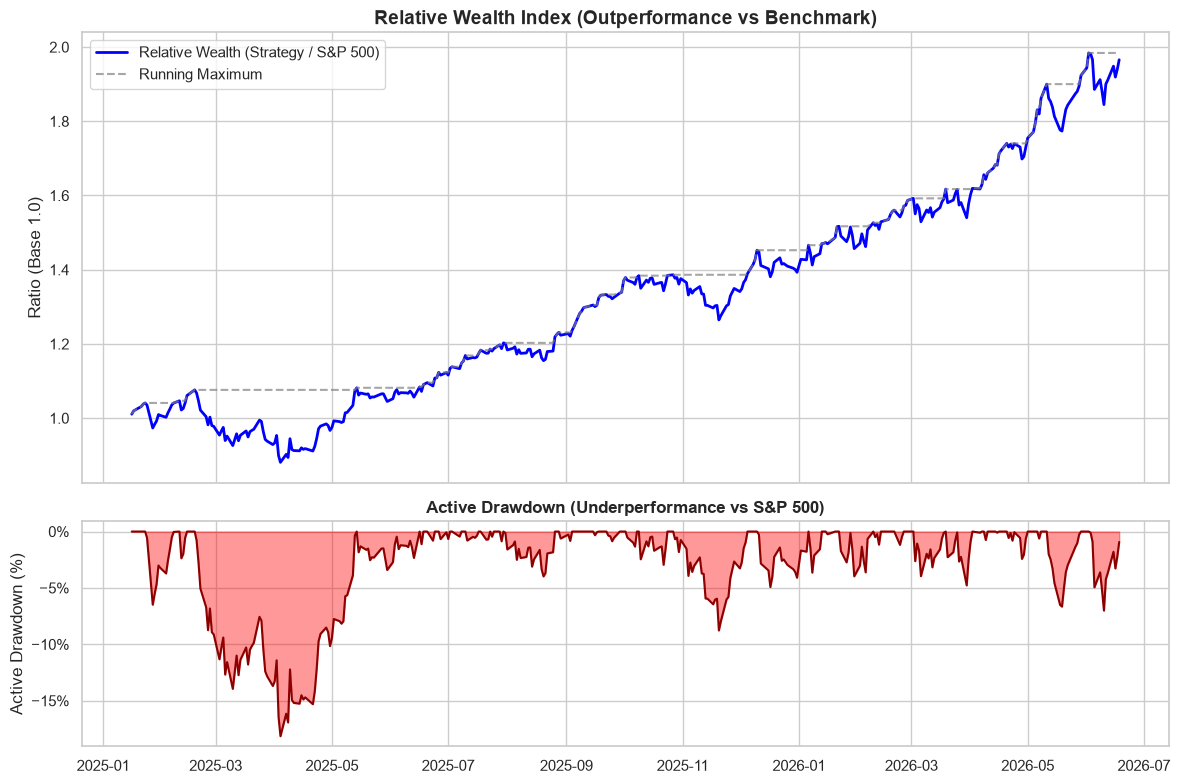

In [19]:
from src.portfolio.attribution import (
    active_drawdown_analysis,
    print_active_drawdown_summary,
    plot_active_drawdown
)

active_dd_result = active_drawdown_analysis(s_strategy, s_bmk_aligned)
print_active_drawdown_summary(active_dd_result)
plot_active_drawdown(active_dd_result)

**Interpretation**: Maximum active drawdown **−18.15%** (consistent with a ~21% tracking error on a 10-stock portfolio); maximum underwater duration **59 trading days** — the strategy never lagged the S&P 500 for more than about a quarter.

**Takeaway:** relative underperformance episodes are sharp but short-lived.

## 8. Robustness Synthesis

This section collects the results of §3 to §7 and grades them without softening. Each test gets one of four verdicts: **Passed**, **Passed with caveats**, **Mixed** or **Not passed**. A failure is reported even when its cause is structural (a long-only, high-beta strategy cannot be expected to survive a bear market): it is explained, not hidden.

Unless stated otherwise, figures refer to the final model (Random Forest, Top 10 Signal Weight, 21-day horizon) over the OOS window, 2025-01-16 to 2026-06-18 (357 trading days).

### 8.1 Evidence that Holds Up

- **Selection bias, Deflated Sharpe (§3). Passed with caveats.** Annualized net Sharpe of 2.47 over 357 daily observations (skewness 0.09, kurtosis 9.96). The Sharpe expected by chance is 1.10 under the conservative trial count (210, full grid) and 1.04 under the defensible one (42, distinct 21-day signals). The deflated PSR is 0.945 and 0.953 respectively. The observed Sharpe is far above what luck alone would produce, but the PSR sits right at the usual 95% threshold: just below it under the conservative count, just above under the defensible one. With a short sample and fat tails, this should be read as "probably not selection bias", not as proof.

- **Training window and horizon (§4). Passed.** All six combinations keep a strongly positive result: net Sharpe between 2.36 and 2.80, CAGR between 82% and 93%, maximum drawdown between 30% and 32%. Nothing collapses when the horizon or window changes. Shorter horizons and the 5-year rolling window score higher, but the Sharpe gap between windows (0.16 to 0.22) is only slightly larger than the gap between the retrained 21d/expanding model (2.36) and the final model (2.47), which is 0.11 and comes from retraining noise alone. The ranking of configurations is therefore not established. The 21-day horizon of the final model is the lowest-scoring horizon within each window, so it was not chosen on these results; changing it now would be selection on the OOS window.

- **Sector universe (§5). Passed with caveats.** The Top 20% selected within each of four sectors beats the equal-weight benchmark of that sector in all four cases. Excess CAGR ranges from +15.5% (Healthcare) to +110.2% (Technology), the Sharpe difference from +0.42 to +1.66, and the information ratio from 0.98 to 2.34. The signal therefore ranks stocks within sectors and is not only a technology rotation. Caveats: the effect is dominated by Technology (CAGR 147%, Sharpe 3.06), while Healthcare reaches an absolute Sharpe of only 0.68 and Financial Services 1.14. Maximum drawdowns are worse than the benchmark's in all four sectors (22% to 37% versus 15% to 26%). Only four sectors and one cut (Top 20, not the Top 10 of the final portfolio) were tested, so this shows within-sector ranking power, not sector neutrality of the final portfolio.

- **Time-series outliers, best 5 days (§6.2). Passed with caveats.** Removing the best 5 days (1.4% of the sample) lowers the strategy's Sharpe from 2.47 to 1.48 (-40%) and the S&P 500's from 1.02 to 0.15 (-86%). The strategy stays clearly positive (CAGR 48.6%). However, its CAGR falls by almost half, and three of its five best days (2025-04-09, 2025-05-12, 2026-03-31) are also among the S&P 500's five best. The strategy's largest days are market days, which is consistent with a beta close to 1.8.

### 8.2 Evidence of Fragility or Ambiguity

- **Cross-sectional outliers, best stock every day (§6.4). Not passed.** Removing the best-contributing stock each day takes the CAGR from 89.75% to 0.26% and the Sharpe from 2.47 to 0.01. The test is severe by construction: it removes the best outcome ex post, every day, from a concentrated portfolio (about 44 positions), and it has no reference portfolio to calibrate against. It is also approximate (gross contributions minus a cost proxy). Even so, it provides no evidence that profits are spread across holdings: almost the entire return comes from the single best stock of each day.

- **Up/down capture (§7.1). Mixed.** The strategy captures 211.7% of up-market moves and 171.4% of down-market moves, a spread of 40.3 points. The asymmetry is positive, but a strategy that loses 1.7 times as much as the market on down days is not defensive. A rough check: a beta of 1.84 plus a constant alpha of about 0.16% per day would imply captures of roughly 207% and 163%, close to what is observed. The spread therefore looks like the alpha intercept rather than genuine convexity. This is an interpretation, not a test.

- **Rolling attribution (§7.2). Passed with caveats.** The 60-day beta has a mean of 1.84 and a range of 1.55 to 2.26, with no spikes: exposure is high but stable. The annualized alpha has a mean of 39.8% and is positive in the vast majority of windows, but its range is -4.8% to +84%, so it is not always positive. Mean tracking error is 21.1%. These are plain OLS point estimates on overlapping windows, not significance tests.

- **Stress resampling (§7.3). Not passed (expected).** In a synthetic stress year the S&P 500 falls 33.5% on average and the strategy 38.8% (95% interval -64.2% to -6.1%). The strategy beats the index in only 26.7% of simulations and is profitable in 1.2% of them. The strategy's loss is only about 1.16 times the index's despite a beta of 1.84, so selection absorbs part of the blow, but it provides no protection against a sustained decline. Caveat: the stress pool is built from the OOS window alone. The 337 overlapping blocks correspond to roughly 17 independent ones, and the stress threshold is a +0.18% 21-day S&P 500 return, so the "stress" blocks are flat-to-down stretches of a bull market, drawn from a handful of distinct episodes.

- **Active drawdown (§7.4). Passed with caveats.** Maximum active drawdown of -18.15% and a longest lag behind the S&P 500 of 59 trading days: relative underperformance episodes are sharp but short. In absolute terms the picture is harsher: the retrained 21d/expanding model shows a maximum drawdown of about -32% and 86 days underwater, and annualized volatility is 33% to 35% in every configuration.

### 8.3 Scorecard

- Selection bias (Deflated Sharpe): **Passed with caveats**
- Training window and horizon: **Passed**
- Sector universe: **Passed with caveats**
- Time-series outliers (best 5 days): **Passed with caveats**
- Cross-sectional outliers (best stock every day): **Not passed**
- Up/down capture: **Mixed**
- Rolling beta, alpha and tracking error: **Passed with caveats**
- Stress resampling: **Not passed** (expected for a long-only, high-beta strategy)
- Active drawdown: **Passed with caveats**

One clean pass, five passes with caveats, one mixed result and two failures. The failures are not marginal, and the passes are mostly qualified. Section 9 draws the conclusions from this balance.

## 9. Conclusions

### 9.1 What the Evidence Supports

- **The signal has ranking content in this sample.** The result is positive in all six window/horizon configurations, beats the sector benchmark in all four sectors tested, and survives the best-days test with a Sharpe of 1.48. The observed Sharpe (2.47) is well above the value expected by chance (1.04 to 1.10), although the deflated PSR (0.945 to 0.953) is only borderline.
- **It does not depend on one parameter choice or on technology alone.** Changing the horizon or the training window does not break the result, and the within-sector tests show that the signal works outside the sector that dominates the aggregate result.
- **Its exposure is stable.** Beta stays between 1.55 and 2.26 across 60-day windows and alpha is positive in most of them, so the performance is not the product of a single episode of high leverage on the market.

### 9.2 What the Evidence Does Not Support

- **The strategy is not defensive or market-neutral.** With a beta of about 1.84, it captures 171% of down-market moves and loses 38.8% in the synthetic stress year against 33.5% for the index. The capture asymmetry is consistent with a constant alpha added to high beta, not with convexity.
- **Breadth across holdings is not demonstrated.** Removing the best stock of each day eliminates essentially all of the return. The test is severe and uncalibrated, but it leaves the question open rather than answering it in the strategy's favour.
- **The ranking of configurations is not established.** Rolling versus expanding windows and shorter versus longer horizons differ by amounts comparable to the unmeasured retraining noise (the 82% versus 89% CAGR gap).
- **The absolute numbers should not be extrapolated.** A CAGR near 90% and a Sharpe near 2.5 come from 357 days of a single, strongly bullish regime, with return kurtosis close to 10.

### 9.3 Limitations

- **One OOS window for everything.** All tests in §4 to §7 reuse the same 357 days. They measure sensitivity to design choices; they are not independent validation, and none of them observes a bear market.
- **Retraining variability is unmeasured.** The gap between the final model and its retrained version is attributed to seeds and boundary names, but not tested directly.
- **The stress pool is thin.** It is built from the OOS window only, from heavily overlapping blocks, and its "stress" threshold is a slightly positive 21-day return.
- **The trial count in the DSR is a judgement.** The conclusion changes from just below to just above the 95% threshold depending on whether 210 or 42 trials are counted.
- **Several tests rely on approximations.** The cross-sectional test uses a cost proxy instead of actual transaction costs, and the Sharpe in the outlier tests is computed as CAGR divided by volatility, without a risk-free rate.

### 9.4 Overall Assessment

The evidence is consistent with a genuine cross-sectional signal rather than a data-mining artifact, but not strong enough to call it proven, and the way it is packaged is a high-beta, long-only, concentrated portfolio that will lose heavily in a prolonged market decline. This notebook supports the signal as a research result. It does not support presenting the strategy as robust, defensive or ready for deployment as a standalone product.

The most informative next steps would be:

1. Repeat the 21d/expanding retraining with several seeds, to size the retraining noise against the differences in §4.
2. Extend the evaluation to earlier years that include a bear market, so that downside behaviour is observed and not only simulated.
3. Evaluate a beta-hedged version of the strategy, to test whether the alpha survives once the market exposure is removed.
4. Calibrate the cross-sectional outlier test against a reference portfolio (for example, a random Top 10 selection), so that its result can be interpreted.